# Employee Promotion Prediction using Random Forest

## Project Overview

This project uses a Random Forest Classification model to predict whether an employee will be promoted based on their work-related and personal information.

The model learns patterns from employee data and predicts the promotion status of a new employee.

## Objective

The objective of this project is to build a Random Forest classification model that predicts whether an employee will be promoted.

The model uses the following information:

- Age
- Experience
- Performance Score
- Training Hours
- Projects Completed
- Job Satisfaction

The target variable is:

- 0 → Not Promoted
- 1 → Promoted

## Dataset Description

The dataset contains information about employees and their work-related characteristics.

### Features

- **Age** – Age of the employee
- **Experience** – Years of work experience
- **Performance_Score** – Employee performance score
- **Training_Hours** – Number of training hours completed
- **Projects_Completed** – Number of projects completed
- **Job_Satisfaction** – Employee job satisfaction score

### Target Variable

- **Promoted** – Promotion status
  - 0 → Not Promoted
  - 1 → Promoted

## Create Dataset

The dataset contains employee information such as age, experience, performance, training, completed projects, and job satisfaction.

The target variable `Promoted` indicates whether an employee was promoted.

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 45,
            24, 27, 29, 31, 34, 37, 39, 41, 44, 46,
            23, 26, 33, 36, 43, 47, 28, 32, 38, 42],

    "Experience": [1, 2, 3, 4, 5, 7, 9, 10, 12, 15,
                   1, 3, 4, 5, 6, 8, 10, 11, 13, 16,
                   2, 3, 5, 7, 12, 14, 4, 6, 9, 11],

    "Performance_Score": [55, 60, 62, 65, 70, 75, 80, 85, 88, 92,
                          58, 63, 68, 72, 74, 78, 83, 87, 90, 94,
                          57, 66, 71, 76, 89, 91, 69, 73, 82, 86],

    "Training_Hours": [10, 15, 18, 20, 25, 30, 35, 40, 45, 50,
                       12, 17, 22, 27, 29, 34, 38, 42, 47, 52,
                       14, 21, 26, 31, 43, 48, 23, 28, 36, 41],

    "Projects_Completed": [1, 1, 2, 2, 3, 4, 5, 6, 7, 8,
                           1, 2, 2, 3, 3, 4, 5, 6, 7, 9,
                           1, 2, 3, 4, 6, 7, 2, 3, 5, 6],

    "Job_Satisfaction": [5, 6, 6, 7, 7, 8, 8, 9, 9, 10,
                         5, 6, 7, 7, 8, 8, 9, 9, 10, 10,
                         6, 6, 7, 8, 9, 9, 7, 8, 8, 9],

    "Promoted": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
                 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
                 0, 1, 1, 1, 1, 1, 0, 1, 1, 1]
})

(df)

,Age,Experience,Performance_Score,Training_Hours,Projects_Completed,Job_Satisfaction,Promoted
0,22,1,55,10,1,5,0
1,25,2,60,15,1,6,0
2,28,3,62,18,2,6,0
3,30,4,65,20,2,7,0
4,32,5,70,25,3,7,1
5,35,7,75,30,4,8,1
6,38,9,80,35,5,8,1
7,40,10,85,40,6,9,1
8,42,12,88,45,7,9,1
9,45,15,92,50,8,10,1


## Understand the Dataset

Before building the machine learning model, we will inspect the dataset to understand its structure, size, data types, statistical information, and target variable distribution.

In [46]:
print("Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nPromotion Distribution:")
print(df["Promoted"].value_counts())

Shape: (30, 7)

First 5 Rows:
   Age  Experience  Performance_Score  Training_Hours  Projects_Completed  \
0   22           1                 55              10                   1   
1   25           2                 60              15                   1   
2   28           3                 62              18                   2   
3   30           4                 65              20                   2   
4   32           5                 70              25                   3   

   Job_Satisfaction  Promoted  
0                 5         0  
1                 6         0  
2                 6         0  
3                 7         0  
4                 7         1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 30 non-null     int64
 1   Experience          30 non-null     int64
 2 

## Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the relationship between employee characteristics and promotion status.

We will visualize how performance, experience, training hours, projects completed, and job satisfaction relate to employee promotions.

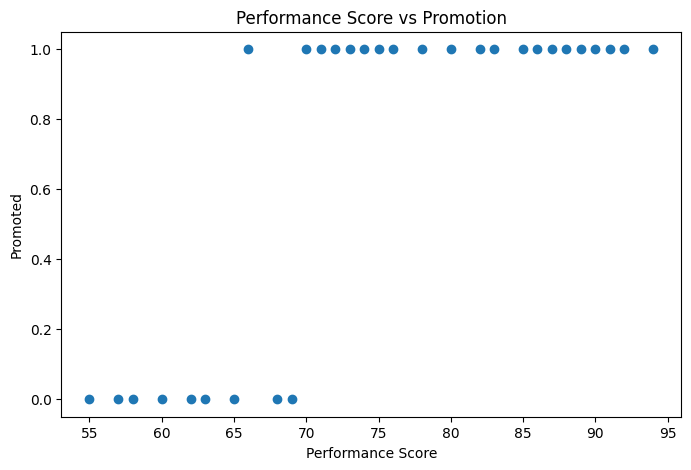

In [47]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Performance_Score"],
    df["Promoted"]
)

plt.xlabel("Performance Score")
plt.ylabel("Promoted")
plt.title("Performance Score vs Promotion")

plt.show()

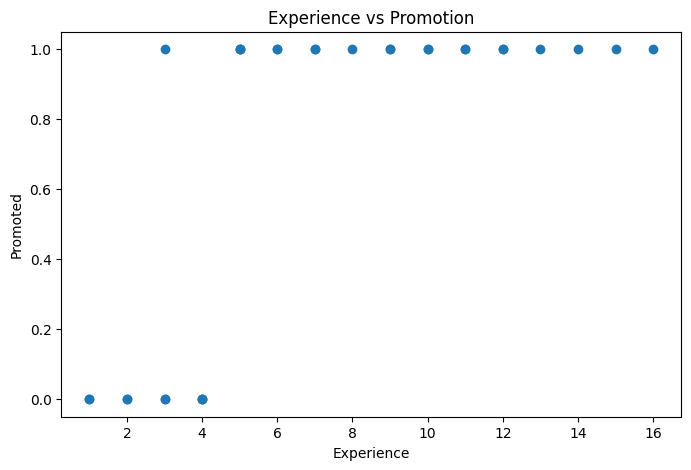

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Experience"],
    df["Promoted"]
)

plt.xlabel("Experience")
plt.ylabel("Promoted")
plt.title("Experience vs Promotion")

plt.show()

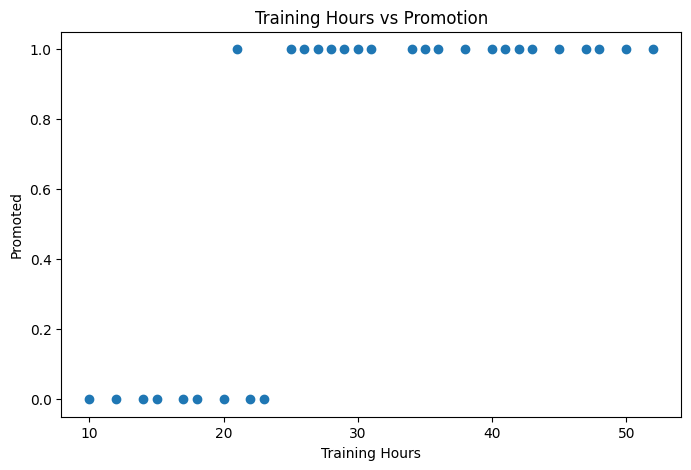

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Training_Hours"],
    df["Promoted"]
)

plt.xlabel("Training Hours")
plt.ylabel("Promoted")
plt.title("Training Hours vs Promotion")

plt.show()

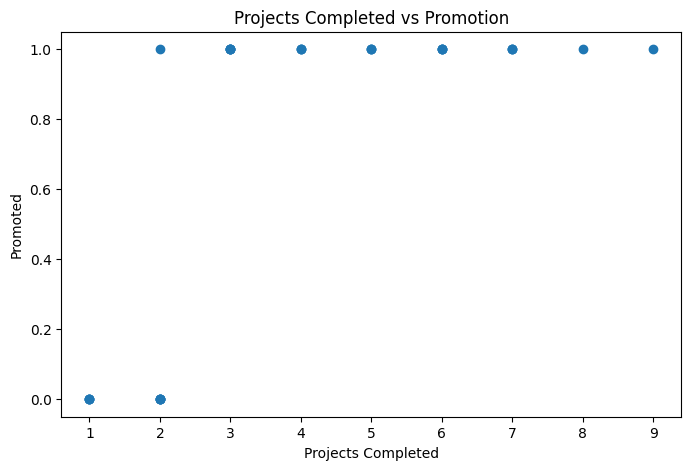

In [50]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Projects_Completed"],
    df["Promoted"]
)

plt.xlabel("Projects Completed")
plt.ylabel("Promoted")
plt.title("Projects Completed vs Promotion")

plt.show()

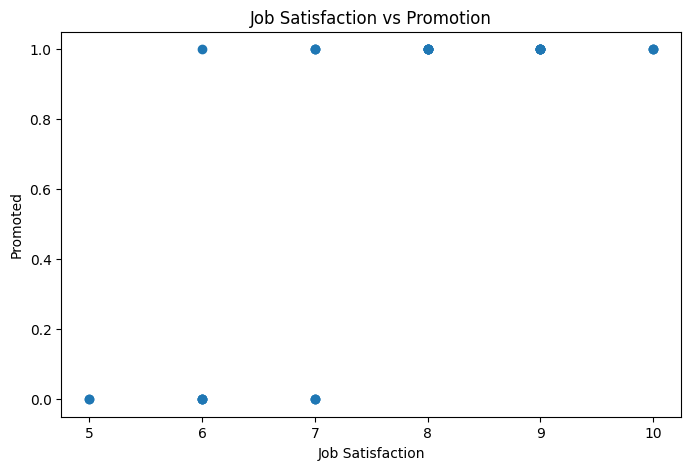

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Job_Satisfaction"],
    df["Promoted"]
)

plt.xlabel("Job Satisfaction")
plt.ylabel("Promoted")
plt.title("Job Satisfaction vs Promotion")

plt.show()

## Select Features and Target

We will select the employee-related features as input variables and `Promoted` as the target variable.

The model will use these features to predict whether an employee will be promoted.

In [52]:
X = df[[
    "Age",
    "Experience",
    "Performance_Score",
    "Training_Hours",
    "Projects_Completed",
    "Job_Satisfaction"
]]

y = df["Promoted"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Age  Experience  Performance_Score  Training_Hours  Projects_Completed  \
0   22           1                 55              10                   1   
1   25           2                 60              15                   1   
2   28           3                 62              18                   2   
3   30           4                 65              20                   2   
4   32           5                 70              25                   3   

   Job_Satisfaction  
0                 5  
1                 6  
2                 6  
3                 7  
4                 7  

Target:
0    0
1    0
2    0
3    0
4    1
Name: Promoted, dtype: int64


## Train-Test Split

The dataset will be divided into training and testing sets.

The training data will be used to train the Random Forest model, while the testing data will be used to evaluate how well the model performs on unseen data.

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 6)
Testing data: (6, 6)


## Train Random Forest Model

We will train a Random Forest Classification model using the training data.

The Random Forest model will create multiple Decision Trees and combine their predictions to make the final promotion prediction.

We will use 100 Decision Trees and set `random_state=42` to make the results reproducible.

In [54]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## Make Predictions

The trained Random Forest model will be used to predict the promotion status of the employees in the testing dataset.

In [55]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[0 1 1 1 0 1]


## Model Evaluation

We will evaluate the performance of our Random Forest model using accuracy, confusion matrix, precision, recall, and F1 score.

In [56]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(conf_matrix)

print("\nPrecision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 1.0

Confusion Matrix:
[[2 0]
 [0 4]]

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


## Feature Importance

Feature importance shows how much each feature contributes to the Random Forest model when making predictions.

A higher feature importance value means that the feature played a greater role in the model's predictions.

In [57]:
importance = model.feature_importances_

print("Feature Importance:")

for feature, value in zip(X.columns, importance):
    print(feature, ":", value)

Feature Importance:
Age : 0.19390593316113386
Experience : 0.1714791584920068
Performance_Score : 0.2103643841817796
Training_Hours : 0.24012202655473222
Projects_Completed : 0.14003086850083754
Job_Satisfaction : 0.04409762910950993


## OOB Evaluation

Random Forest uses bootstrap sampling to create different training datasets for its Decision Trees.

Some training samples are not selected for a particular tree. These samples are called **Out-of-Bag (OOB) samples**.

We can use these OOB samples to estimate the model's performance without using a separate validation dataset.

In [58]:
oob_model = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42
)

oob_model.fit(X_train, y_train)

print("OOB Score:", oob_model.oob_score_)

OOB Score: 0.9166666666666666


## Hyperparameter Tuning

Hyperparameter tuning is used to find better settings for the Random Forest model.

Important Random Forest hyperparameters include:

- **n_estimators** – Number of Decision Trees in the Random Forest
- **max_depth** – Maximum depth of each Decision Tree
- **min_samples_split** – Minimum number of samples required to split a node
- **min_samples_leaf** – Minimum number of samples required in a leaf

We will use GridSearchCV and RandomizedSearchCV to find suitable hyperparameter combinations and improve the model's generalization performance.

## GridSearchCV

GridSearchCV tests all possible combinations of the selected hyperparameter values.

For each combination, cross-validation is used to evaluate the model. The combination with the best average cross-validation score is selected as the best configuration.

In [59]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Best CV Score: 0.9099999999999999


## Best Estimator

The `best_estimator_` attribute returns the Random Forest model configured with the best hyperparameters found by GridSearchCV.

We will use this optimized model to make predictions on the test data.

In [60]:
best_model = grid_search.best_estimator_

print("Best Model:")
print(best_model)

Best Model:
RandomForestClassifier(max_depth=5, n_estimators=50, random_state=42)


## Evaluate Tuned Random Forest

The tuned Random Forest model will be evaluated on the test dataset using accuracy, confusion matrix, precision, recall, and F1 score.

The test dataset was not used during hyperparameter tuning, so it provides an unbiased evaluation of the final model's performance on unseen data.

In [61]:
y_pred_tuned = best_model.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
conf_matrix_tuned = confusion_matrix(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)

print("Tuned Model Accuracy:", accuracy_tuned)

print("\nConfusion Matrix:")
print(conf_matrix_tuned)

print("\nPrecision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)

Tuned Model Accuracy: 1.0

Confusion Matrix:
[[2 0]
 [0 4]]

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


## RandomizedSearchCV

RandomizedSearchCV randomly selects a specified number of hyperparameter combinations from a given search space instead of testing every possible combination.

It is especially useful when the hyperparameter search space is large because it can explore different combinations with fewer model fits than GridSearchCV.

In [62]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [50, 100, 200, 300, 500],
    "max_depth": [5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)

Best Parameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 5}
Best CV Score: 0.9099999999999999


## Best Randomized Model

The `best_estimator_` attribute returns the Random Forest model configured with the best hyperparameters found by RandomizedSearchCV.

We will use this model for the final test evaluation.

In [63]:
random_best_model = random_search.best_estimator_

print("Best Randomized Model:")
print(random_best_model)

Best Randomized Model:
RandomForestClassifier(max_depth=5, min_samples_leaf=2, n_estimators=500,
                       random_state=42)


## Final Model Evaluation

The best Random Forest model obtained from RandomizedSearchCV will be evaluated on the test dataset.

We will use accuracy, confusion matrix, precision, recall, and F1 score to measure the final model's performance.

In [64]:
y_pred_random = random_best_model.predict(X_test)

final_accuracy = accuracy_score(y_test, y_pred_random)
final_conf_matrix = confusion_matrix(y_test, y_pred_random)
final_precision = precision_score(y_test, y_pred_random)
final_recall = recall_score(y_test, y_pred_random)
final_f1 = f1_score(y_test, y_pred_random)

print("Final Model Accuracy:", final_accuracy)

print("\nConfusion Matrix:")
print(final_conf_matrix)

print("\nPrecision:", final_precision)
print("Recall:", final_recall)
print("F1 Score:", final_f1)

Final Model Accuracy: 1.0

Confusion Matrix:
[[2 0]
 [0 4]]

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


## Predict a New Employee

We will use the trained Random Forest model to predict whether a new employee will be promoted based on their age, experience, performance, training hours, completed projects, and job satisfaction.

In [65]:
new_employee = pd.DataFrame({
    "Age": [30],
    "Experience": [5],
    "Performance_Score": [75],
    "Training_Hours": [30],
    "Projects_Completed": [4],
    "Job_Satisfaction": [8]
})

prediction = random_best_model.predict(new_employee)

print("Prediction:", prediction)

if prediction[0] == 1:
    print("The employee is predicted to be Promoted.")
else:
    print("The employee is predicted to be Not Promoted.")

Prediction: [1]
The employee is predicted to be Promoted.


## Conclusion

In this project, we built a Random Forest Classification model to predict whether an employee will be promoted.

The model was trained using employee-related features such as age, experience, performance score, training hours, projects completed, and job satisfaction.

We evaluated the model using accuracy, confusion matrix, precision, recall, and F1 score. We also analyzed feature importance and evaluated the model using Out-of-Bag (OOB) scoring.

Finally, we used GridSearchCV and RandomizedSearchCV for hyperparameter tuning and used the best Random Forest model to predict the promotion status of a new employee.